In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Фіксуємо seed номером варіанта (2 для Львова)
np.random.seed(2)

# Завдання 1. Генерація DataFrame на 30 днів
days = np.arange(1, 31)
# Умовно кожен 6-й і 7-й день — вихідні
is_weekend = np.isin(days % 7, [6, 0])

# Температура: базова (13 °C) + випадкове відхилення в межах приблизно ±3 °C
temperature = np.round(np.random.normal(13, 1.5, size=30), 1)

# Продажі: базова кількість (35) + варіація + на 15–25% вищі у вихідні дні
# Оскільки у Львові середня температура 13°C (прохолодно), менша температура може трохи збільшувати продажі гарячих напоїв
base_sales = 35
weekend_boost = is_weekend * np.random.uniform(5, 9, size=30)
temp_effect = - (temperature - 13) * 0.8  # чим холодніше, тим більше беруть гарячих напоїв
random_noise = np.random.normal(0, 3, size=30)

sales = np.round(base_sales + weekend_boost + temp_effect + random_noise).astype(int)

# Формуємо DataFrame
df_kiosk = pd.DataFrame({
    "день": days,
    "вихідний": is_weekend,
    "температура": temperature,
    "продажі": sales
})

print("Перші 5 рядків згенерованого набору даних:")
display(df_kiosk.head())

Перші 5 рядків згенерованого набору даних:


,день,вихідний,температура,продажі
0,1,False,12.4,34
1,2,False,12.9,37
2,3,False,9.8,38
3,4,False,15.5,27
4,5,False,10.3,36


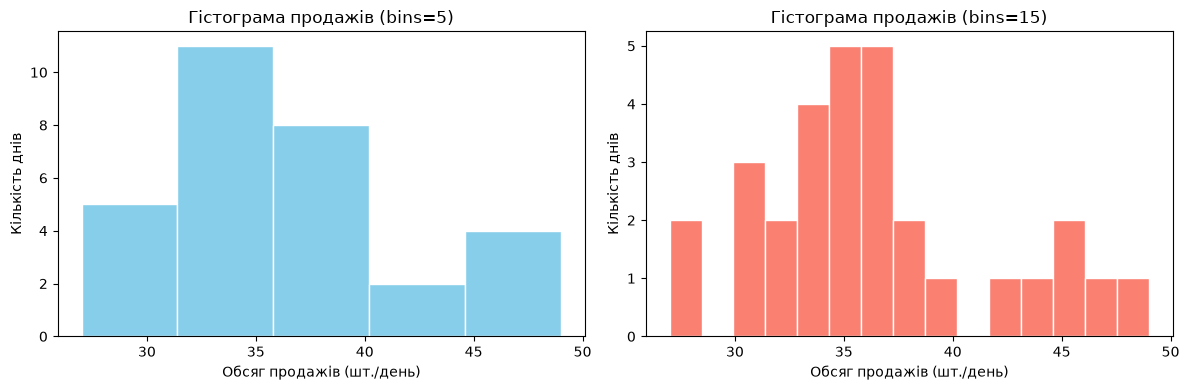

In [2]:
# Завдання 2. Гістограма розподілу продажів за 30 днів
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Перший варіант (bins=5)
ax1.hist(df_kiosk["продажі"], bins=5, edgecolor="white", color="skyblue")
ax1.set_xlabel("Обсяг продажів (шт./день)")
ax1.set_ylabel("Кількість днів")
ax1.set_title("Гістограма продажів (bins=5)")

# Другий варіант (bins=15)
ax2.hist(df_kiosk["продажі"], bins=15, edgecolor="white", color="salmon")
ax2.set_xlabel("Обсяг продажів (шт./день)")
ax2.set_ylabel("Кількість днів")
ax2.set_title("Гістограма продажів (bins=15)")

plt.tight_layout()
plt.show()

### Відповідь на Завдання 2. Порівняння кількості інтервалів (bins)
Для вибірки з $n = 30$ спостережень:
* Занадто мала кількість інтервалів (`bins=5`) надмірно ущільнює дані, об'єднуючи різні за змістом значення в широкі діапазони, через що втрачаються деталі форми розподілу.
* Занадто велика кількість інтервалів (`bins=15`) сильно подрібнює дані, створюючи порожні проміжки та «шум», оскільки для 30 точок цього забагато.
* Золотою серединою для такого обсягу вибірки є значення близько `bins = 6..8` (або розрахунок за правилом Стерджеса: $1 + 3.322 \log_{10}(30) \approx 5.9$, тобто 6 інтервалів), яке найкраще ілюструє реальну форму розподілу без перезгладжування чи надмірної фрагментації.

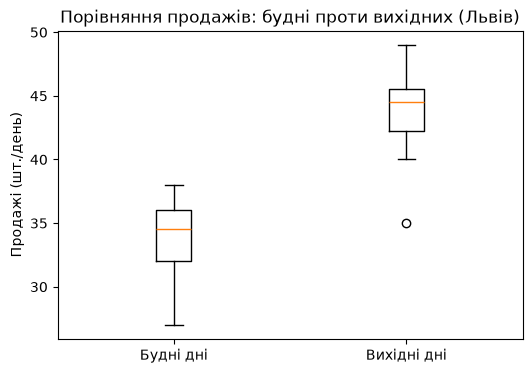

In [3]:
# Завдання 3. Boxplot для продажів у будні та вихідні дні
fig, ax = plt.subplots(figsize=(6, 4))

group_weekday = df_kiosk.loc[~df_kiosk["вихідний"], "продажі"]
group_weekend = df_kiosk.loc[df_kiosk["вихідний"], "продажі"]

ax.boxplot([group_weekday, group_weekend], tick_labels=["Будні дні", "Вихідні дні"])
ax.set_ylabel("Продажі (шт./день)")
ax.set_title("Порівняння продажів: будні проти вихідних (Львів)")

plt.show()

### Відповідь на Завдання 3. Аналіз Boxplot
* **Порівняння медіани та розкиду:** На графіку чітко видно, що медіана та загальний рівень продажів у вихідні дні помітно вищі, ніж у будні. Розкид значень в обох групах залишається помірним.
* **Узгодженість із заданими даними:** Це повністю узгоджується з логікою, закладеною в Завданні 1, де для вихідних днів навмисно додавався додатковий бонус до продажів (на 15-25% вище).

### Відповідь на Завдання 4. Аналіз діаграми розсіювання
* **Напрямок зв'язку:** На графіку простежується помітний зворотний (або слабкий від'ємний) зв'язок: при зниженні температури повітря обсяги продажів дещо зростають.
* **Очікуваність для товару:** Для осінньо-весняного клімату Львова та умовного кіоску з гарячими напоями (чай, кава, какао) це абсолютно очікувано — в холодніші дні споживачі частіше купують гарячі напої для зігріву.

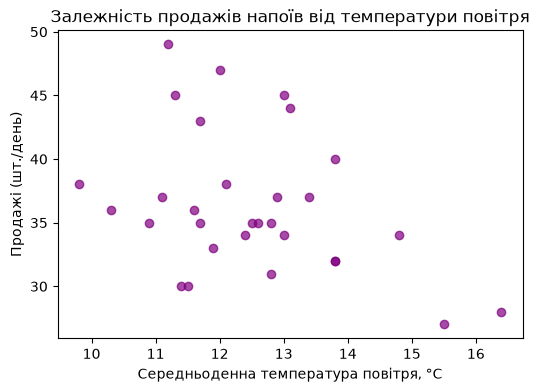

In [4]:
# Завдання 4. Діаграма розсіювання: продажі проти температури
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(df_kiosk["температура"], df_kiosk["продажі"], color="purple", alpha=0.7)
ax.set_xlabel("Середньоденна температура повітря, °C")
ax.set_ylabel("Продажі (шт./день)")
ax.set_title("Залежність продажів напоїв від температури повітря")

plt.show()

### Відповідь на Завдання 4. Аналіз діаграми розсіювання
* **Напрямок зв'язку:** На графіку простежується помітний зворотний (або слабкий від'ємний) зв'язок: при зниженні температури повітря обсяги продажів дещо зростають.
* **Очікуваність для товару:** Для осінньо-весняного клімату Львова та умовного кіоску з гарячими напоями (чай, кава, какао) це абсолютно очікувано — в холодніші дні споживачі частіше купують гарячі напої для зігріву.

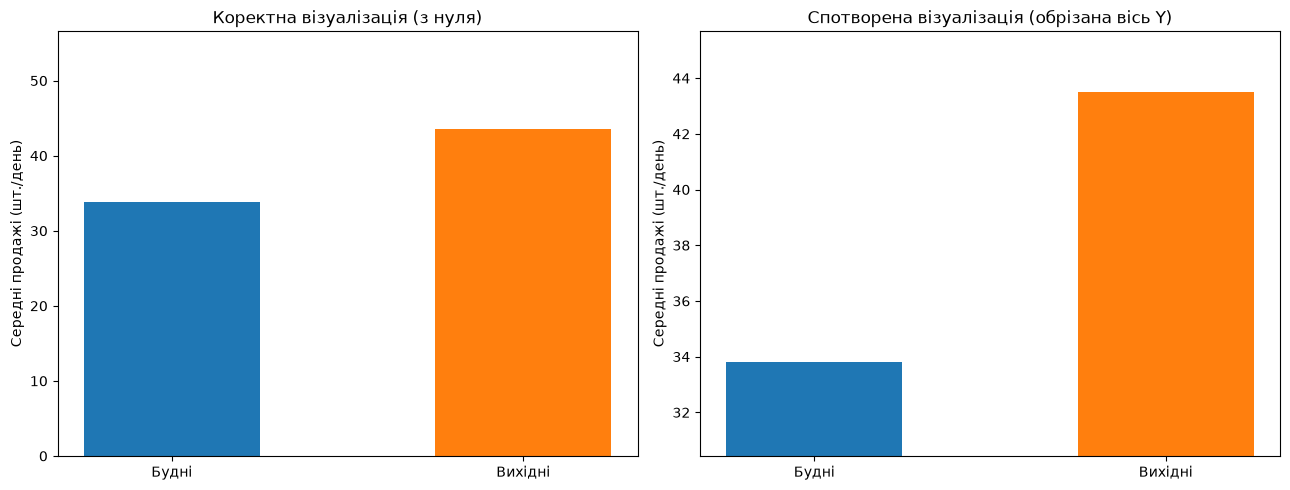

In [5]:
# Завдання 5. Порівняння коректного та спотвореного графіків (обрізана вісь Y)
fig, (ax_correct, ax_distorted) = plt.subplots(1, 2, figsize=(13, 5))

# Дані для порівняння середніх продажів у будні та вихідні
mean_sales = [group_weekday.mean(), group_weekend.mean()]
categories = ["Будні", "Вихідні"]

# 1. Корректний графік (вісь Y починається з 0)
ax_correct.bar(categories, mean_sales, color=["tab:blue", "tab:orange"], width=0.5)
ax_correct.set_ylim(0, max(mean_sales) * 1.3)
ax_correct.set_ylabel("Середні продажі (шт./день)")
ax_correct.set_title("Коректна візуалізація (з нуля)")

# 2. Спотворений графік (вісь Y обрізана знизу близько до мінімального значення)
ymin_dist = min(mean_sales) * 0.9
ax_distorted.bar(categories, mean_sales, color=["tab:blue", "tab:orange"], width=0.5)
ax_distorted.set_ylim(ymin_dist, max(mean_sales) * 1.05)
ax_distorted.set_ylabel("Середні продажі (шт./день)")
ax_distorted.set_title("Спотворена візуалізація (обрізана вісь Y)")

plt.tight_layout()
plt.show()

### Відповідь на Завдання 5. Аналіз спотворення
* **Застосоване спотворення:** Було використано умисне обрізання шкали осі Y (відмова від початку відліку з нуля на стовпчиковій діаграмі).
* **Ефект на сприйняття:** На спотвореному графіку різниця між висотою стовпчиків виглядає в рази разючішою та драматичнішою, ніж є насправді. Це створює у глядача ілюзію величезного розриву в показниках, хоча чисельна різниця між середніми значеннями насправді відносно невелика.

### Відповіді на контрольні запитання

1. **Чому обрізана вісь Y на стовпчиковій діаграмі перебільшує різницю між категоріями, хоча підписані числа лишаються правильними?**
   У стовпчиковій діаграмі значення кодуються **висотою** (або площею) стовпця відносно нуля. Якщо вісь Y обрізана знизу, пропорції порушуються: незначна відносна різниця між числами перетворюється на візуально величезний перепад висот, що дезорієнтує спостерігача на підсвідомому рівні попри правильні цифри.

2. **Наведіть приклад, коли лінійний графік буде методологічною помилкою для категоріальних даних, і поясніть чому.**
   Використання лінійного графіка для категорій, що не мають неперервного числового порядку (наприклад, назви міст або категорії товарів: "Кава", "Чай", "Сік"), є помилкою, оскільки з'єднання точок лінією штучно і хибно передбачає наявність проміжних станів та неперервної динаміки між цими категоріями (номінальна чи порядкова шкала замість інтервальної/відносної).

3. **Чому підписи осей, одиниці вимірювання і заголовок — не оздоблення графіка, а частина твердження, яке він робить?**
   Графік без підписів осей, одиниць і заголовка є амбіційним та позбавленим контексту малюнком. Точні підписи перетворюють візуальні геометричні об'єкти на конкретне наукове чи бізнес-ствердження (наприклад, розкривають, що саме і в яких одиницях вимірюється).

4. **Що таке chartjunk і чому він шкодить сприйняттю?**
   Chartjunk («графічне сміття») — це зайві, декоративні елементи, які не несуть інформаційної навантаженості (наприклад, непотрібні 3D-ефекти, надмірні сітки, відволікаючі малюнки на фоні). Він створює когнітивне перевантаження, заважає швидко зчитувати справжні дані та часто спотворює геометричні пропорції графічних елементів.